In [1]:
import pandas as pd

import matplotlib.pyplot as plot
import matplotlib.dates as mdates
import seaborn as sns
import time
from datetime import datetime, timedelta, date
import teradata
import numpy as np


start = time.time() 
system = "TERADBAWS.sicredi.net"
user = "P_USR_DL_GESTAO_RECURSOS"
passw = "JAW0b71329aadade35365afc6X"
udaExec = teradata.UdaExec (appName="TESTE", version="1.0", logConsole=False)
session = udaExec.connect(method="odbc", system=system,
        username=user, password=passw, Authentication="TDNEGO");

In [2]:
fras = """
SELECT DU_REF.DT AS DT_REF, DU.DT, DU.NUM - DU_REF.NUM AS VERTICE 
, FRA.TX_FRA*100 AS TX_FRA


FROM DL_GESTAO_RECURSOS.DU DU_REF
LEFT JOIN DL_GESTAO_RECURSOS.DU DU ON DU.NUM >= DU_REF.NUM AND DU.NUM <= DU_REF.NUM + 504
INNER JOIN (select DATA AS DT
, COALESCE(LAG(VERTICE,1) OVER (PARTITION BY DATA ORDER BY VERTICE),0) AS VERTICE_A
, VERTICE as VERTICE_B
From DL_GESTAO_RECURSOS.CURVA) LISTA ON LISTA.DT =  DU_REF.DT AND (DU.NUM - DU_REF.NUM) >= LISTA.VERTICE_A AND (DU.NUM - DU_REF.NUM) < LISTA.VERTICE_B
LEFT JOIN DL_GESTAO_RECURSOS.VW_FRA_VERTICE_FIXO FRA ON FRA.DT = DU_REF.DT AND FRA.CONTRATO_A = LISTA.VERTICE_A AND FRA.CONTRATO_B = LISTA.VERTICE_B
WHERE DU_REF.DT = '2005-08-15'
ORDER BY DU.DT
"""


In [3]:
curva = """
select CRV.DATA AS DT_REF, DU.DT, CRV.TAXA, CRV.VERTICE
From DL_GESTAO_RECURSOS.CURVA CRV
INNER join (SELECT DU_REF.DT AS DT_REF, DU.DT, DU.NUM - DU_REF.NUM AS VERTICE 
FROM DL_GESTAO_RECURSOS.DU DU_REF
LEFT JOIN DL_GESTAO_RECURSOS.DU DU ON DU.NUM >= DU_REF.NUM AND DU.NUM <= DU_REF.NUM + 504) DU ON DU.DT_REF=CRV.DATA AND DU.VERTICE=CRV.VERTICE
WHERE CRV.DATA = '2005-08-15'
order by CRV.vertice
"""

In [4]:
cdi = """
SELECT DU_REF.DT AS DT_REF, DU.DT, DU.NUM - DU_REF.NUM AS VERTICE 
, IDX.VALOR
FROM DL_GESTAO_RECURSOS.DU DU_REF
LEFT JOIN DL_GESTAO_RECURSOS.DU DU ON DU.NUM >= DU_REF.NUM AND DU.NUM <= DU_REF.NUM + 504
LEFT JOIN DL_GESTAO_RECURSOS.IDX_INDEX IDX ON IDX.DATA = DU.DT AND IDX.CODINDEX = 'CDI'
WHERE DU_REF.DT = '2005-08-15'
ORDER BY VERTICE
"""

In [5]:
FRA = pd.read_sql(fras, session) 
FRA.DT = pd.to_datetime(FRA.DT, format='%Y-%m-%d')
pd.set_option('mode.chained_assignment', None)
FRA = FRA.sort_values(by=['DT'])

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_28692\1774285959.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  FRA = pd.read_sql(fras, session)


In [6]:
CURVA = pd.read_sql(curva, session) 
CURVA.DT = pd.to_datetime(CURVA.DT, format='%Y-%m-%d')
CURVA = CURVA.sort_values(by=['DT'])
pd.set_option('mode.chained_assignment', None)

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_28692\1224312573.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  CURVA = pd.read_sql(curva, session)


In [7]:
df_cdi = pd.read_sql(cdi, session) 
df_cdi.DT = pd.to_datetime(df_cdi.DT, format='%Y-%m-%d')
df_cdi = df_cdi.sort_values(by=['DT'])
df_cdi['LN'] = np.log(df_cdi['VALOR']/3000+1)
df_cdi['VALOR_252'] = (np.power(df_cdi['VALOR']/3000+1,252)-1)*100
df_cdi['VALOR_ACUM'] = (np.power(np.exp(df_cdi['LN'].cumsum(skipna=False)),252/(df_cdi.index+1))-1)*100
pd.set_option('mode.chained_assignment', None)

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_28692\3570562386.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_cdi = pd.read_sql(cdi, session)


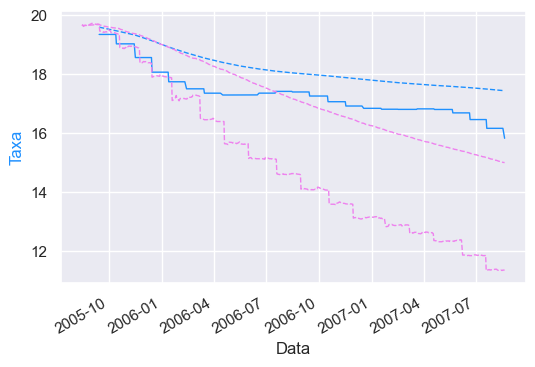

In [8]:
FRA = FRA.sort_values(by=['DT'])
CURVA = CURVA.sort_values(by=['DT'])
df_cdi = df_cdi.sort_values(by=['DT'])


sns.set(style="darkgrid", palette="Set2")
plot.rcParams['figure.figsize'] = (6,4)

fig, ax = plot.subplots()
ax.plot(FRA.DT,FRA['TX_FRA'], marker = '', color='dodgerblue',linestyle='-',linewidth=1,)
ax.plot(CURVA.DT,CURVA['TAXA']*100, marker='', color='dodgerblue',linestyle='--',linewidth=1)
ax.plot(df_cdi.DT,df_cdi['VALOR_252'], marker='', color='violet',linestyle='--',linewidth=1)
ax.plot(df_cdi.DT,df_cdi['VALOR_ACUM'], marker='', color='violet',linestyle='--',linewidth=1)
ax.set_ylabel('Taxa', color='dodgerblue')


plot.xlabel('Data')
fig.autofmt_xdate()
ax.fmt_xdata = mdates.DateFormatter('%Y-%m')
plot.show()


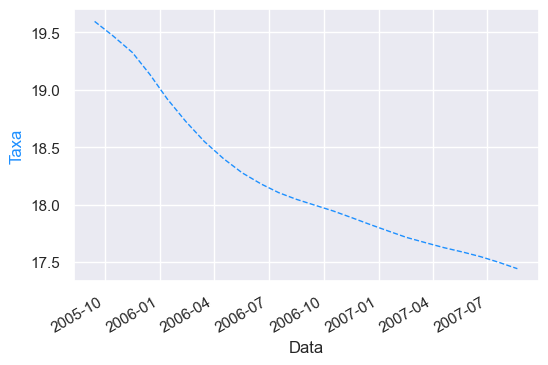

In [9]:
sns.set(style="darkgrid", palette="Set2")
plot.rcParams['figure.figsize'] = (6,4)

fig, ax = plot.subplots()
ax.plot(CURVA.DT,CURVA['TAXA']*100, marker='', color='dodgerblue',linestyle='--',linewidth=1)
ax.set_ylabel('Taxa', color='dodgerblue')


plot.xlabel('Data')
fig.autofmt_xdate()
ax.fmt_xdata = mdates.DateFormatter('%Y-%m')
plot.show()

In [10]:
curva = """
select CRV.DATA AS DT_REF, DU.DT, CRV.TAXA*100 as TAXA, CRV.VERTICE
From DL_GESTAO_RECURSOS.CURVA CRV
INNER join (SELECT DU_REF.DT AS DT_REF, DU.DT, DU.NUM - DU_REF.NUM AS VERTICE 
FROM DL_GESTAO_RECURSOS.DU DU_REF
LEFT JOIN DL_GESTAO_RECURSOS.DU DU ON DU.NUM >= DU_REF.NUM AND DU.NUM <= DU_REF.NUM + 2000) DU ON DU.DT_REF=CRV.DATA AND DU.VERTICE=CRV.VERTICE
WHERE CRV.DATA IN ('2023-01-02','2023-02-03','2023-06-26')
order by CRV.vertice
"""

In [11]:
CURVA = pd.read_sql(curva, session) 
CURVA.DT = pd.to_datetime(CURVA.DT, format='%Y-%m-%d')
CURVA = CURVA.sort_values(by=['DT'])
pd.set_option('mode.chained_assignment', None)

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_28692\1224312573.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  CURVA = pd.read_sql(curva, session)


C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


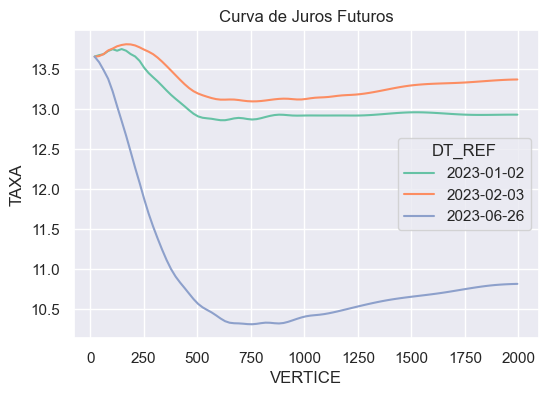

In [12]:

df_grafico  = CURVA
#df_grafico = df_grafico[df_grafico.FL_FIM_MES == 1]


sns.set(style="darkgrid", palette="Set2")
ax1 = sns.lineplot(x='VERTICE', y='TAXA', data=df_grafico, hue='DT_REF')
ax1.set(title='Curva de Juros Futuros')
plot.show()

In [13]:
implicita = """
select DT AS DT_REF, DU AS VERTICE, TX_REAL*100 AS TX_REAL, TX_IMPLICITA*100 AS TX_IMPLICITA 
from dl_Gestao_recursos.vw_dap_implicita
where dt in ('2023-01-02','2023-02-03','2023-06-26') AND FUVCT_CD <> 'Q60' AND VERTICE > 30
"""

In [14]:
IMPLICITA = pd.read_sql(implicita, session) 
IMPLICITA.DT_REF = pd.to_datetime(IMPLICITA.DT_REF, format='%Y-%m-%d')
IMPLICITA = IMPLICITA.sort_values(by=['DT_REF'])
pd.set_option('mode.chained_assignment', None)

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_28692\1747840584.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  IMPLICITA = pd.read_sql(implicita, session)


C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode

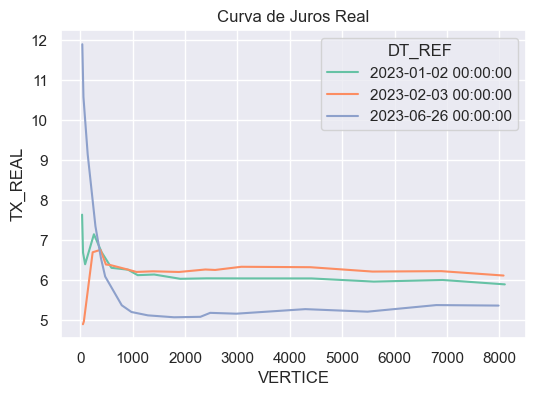

In [15]:

df_grafico  = IMPLICITA
#df_grafico = df_grafico[df_grafico.FL_FIM_MES == 1]


sns.set(style="darkgrid", palette="Set2")
ax1 = sns.lineplot(x='VERTICE', y='TX_REAL', data=df_grafico, hue='DT_REF')
ax1.set(title='Curva de Juros Real')
plot.show()

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode

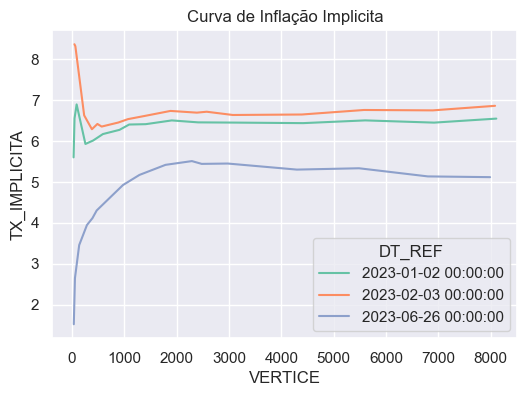

In [16]:

df_grafico  = IMPLICITA
#df_grafico = df_grafico[df_grafico.FL_FIM_MES == 1]


sns.set(style="darkgrid", palette="Set2")
ax1 = sns.lineplot(x='VERTICE', y='TX_IMPLICITA', data=df_grafico, hue='DT_REF')
ax1.set(title='Curva de Inflação Implicita')
plot.show()